
GROUP SIZES (Radius = 6 cm)

Total videos per treatment:
Treatment
SH AL    11
SH FD    18
GH FD    10
GH AL    10

Videos with valid paired baseline/approach data (SS):
Treatment
SH AL    11
SH FD    18
GH FD    10
GH AL    10

Videos with valid paired baseline/approach data (FS):
Treatment
SH AL    11
SH FD    18
GH FD    10
GH AL    10


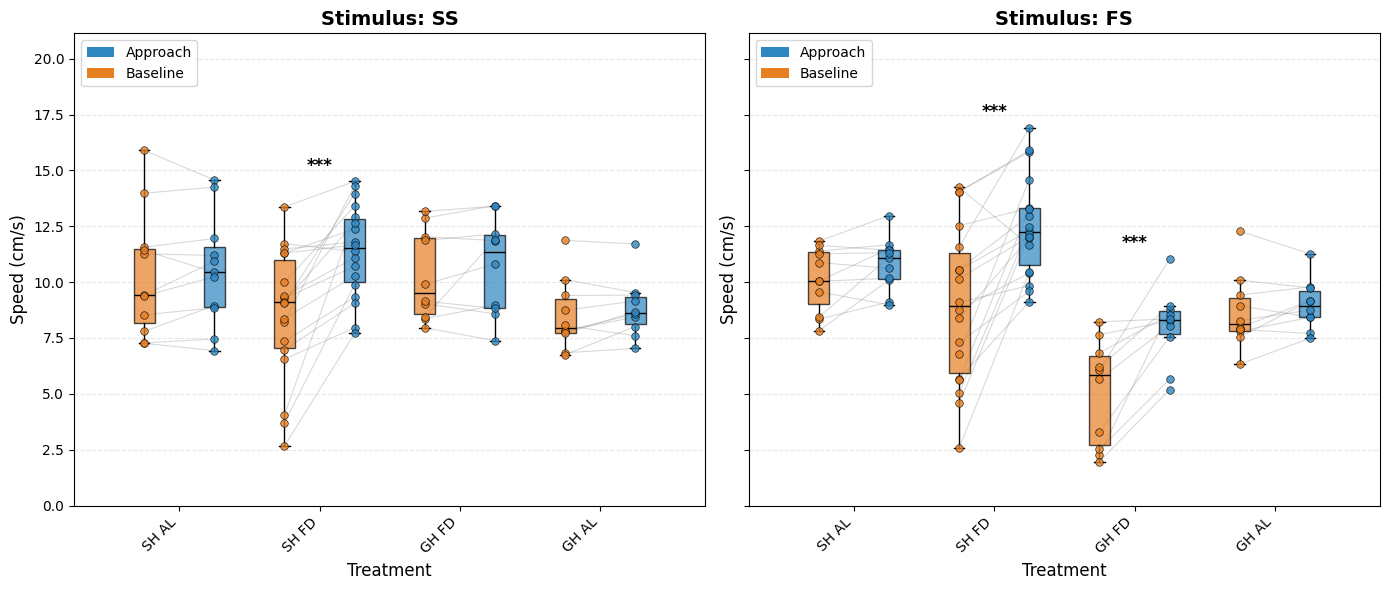


PAIRED APPROACH vs BASELINE (Radius = 6 cm) - Manual Alignment

--- SS ---
  SH AL: p = 0.4954 ns
  SH FD: p = 0.0001 ***
  GH FD: p = 0.3223 ns
  GH AL: p = 0.1529 ns

--- FS ---
  SH AL: p = 0.0544 ns
  SH FD: p = 0.0003 ***
  GH FD: p = 0.0009 ***
  GH AL: p = 0.2341 ns

✅ Perfectly aligned figure saved to: approach_vs_baseline_perfect_alignment_manual.png


In [3]:
#plot for paired test between approach and baseline velocities for mice
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import shapiro, ttest_rel, wilcoxon

# =============================================================================
# CONFIGURATION
# =============================================================================
SUMMARY_CSV = "analysis_plots_parametric/approach_speed_summary_all_radii.csv"
RADIUS = 6
TREATMENT_ORDER = ['SH AL', 'SH FD', 'GH FD', 'GH AL']
OUTPUT_FIG = "approach_vs_baseline_perfect_alignment_manual.png"
COLORS = {'Approach': '#2E86C1', 'Baseline': '#E67E22'}
ALPHA_LINES = 0.3

# =============================================================================
# LOAD & FILTER
# =============================================================================
df = pd.read_csv(SUMMARY_CSV)
df = df[df['radius'] == RADIUS]
df = df[df['Treatment'] != 'unknown']
df = df[df['Treatment'].isin(TREATMENT_ORDER)]
df['Treatment'] = pd.Categorical(df['Treatment'], categories=TREATMENT_ORDER, ordered=True)
# =============================================================================
# GROUP COUNTS
# =============================================================================
print("\n" + "="*50)
print(f"GROUP SIZES (Radius = {RADIUS} cm)")
print("="*50)

# Total videos per treatment
counts_total = df.groupby('Treatment', observed=True)['video'].nunique()
print("\nTotal videos per treatment:")
print(counts_total.to_string())

# Videos with valid (non-NaN) paired data per treatment, per stimulus
for stim in ['SS', 'FS']:
    base_col = f"baseline_speed_{stim}"
    appr_col = f"approach_speed_{stim}"
    valid_df = df.dropna(subset=[base_col, appr_col])
    counts_valid = valid_df.groupby('Treatment', observed=True)['video'].nunique()
    print(f"\nVideos with valid paired baseline/approach data ({stim}):")
    print(counts_valid.reindex(TREATMENT_ORDER).to_string())
# Define phases and stimuli
stimuli = ['SS', 'FS']
phases = ['Baseline', 'Approach']

# =============================================================================
# CREATE PLOT WITH MANUAL POSITIONS
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
p_vals = {}

for ax_idx, stim in enumerate(stimuli):
    ax = axes[ax_idx]
    # For each treatment, we will have two x-positions: baseline at x-0.2, approach at x+0.2 (or similar)
    # We'll place treatments at x=0,1,2,3, and then offset by +/-0.25.
    treat_positions = np.arange(len(TREATMENT_ORDER))
    offset = 0.25   # half of the gap between phases
    
    # Prepare data for boxplots: we need lists of values for each phase per treatment
    data_groups = []
    x_positions = []
    all_points = {}  # store (video, treatment, phase) -> speed for line drawing
    
    for i, treat in enumerate(TREATMENT_ORDER):
        treat_df = df[df['Treatment'] == treat]
        # For each phase
        for phase in phases:
            col = f"{phase.lower()}_speed_{stim}"  # e.g., baseline_speed_SS
            # Actually our columns are approach_speed_SS, baseline_speed_SS
            col_name = f"{phase.lower()}_speed_{stim}" if phase == 'Approach' else f"{phase.lower()}_speed_{stim}"
            # But in df they are approach_speed_SS and baseline_speed_SS
            # So we use mapping:
            if phase == 'Approach':
                col_name = f"approach_speed_{stim}"
            else:
                col_name = f"baseline_speed_{stim}"
            vals = treat_df[col_name].dropna().values
            # x position: treat_position + offset if phase=='Approach' else treat_position - offset
            x_pos = treat_positions[i] + (offset if phase == 'Approach' else -offset)
            data_groups.append(vals)
            x_positions.append(x_pos)
            # Store for lines
            for vid, spd in zip(treat_df['video'], vals):
                key = (vid, treat, phase)
                # Keep only one per video per phase (should be one)
                all_points[key] = spd
    
    # Now draw boxplots using matplotlib's boxplot (avoid seaborn dodge)
    bp = ax.boxplot(data_groups, positions=x_positions, widths=0.15,
                    patch_artist=True, showfliers=False,
                    boxprops=dict(linewidth=1),
                    whiskerprops=dict(linewidth=1),
                    capprops=dict(linewidth=1),
                    medianprops=dict(linewidth=1, color='black'))
    # Set colors for each box
    for i, box in enumerate(bp['boxes']):
        phase = phases[i % 2]  # since we alternate baseline, approach, baseline, approach...
        box.set_facecolor(COLORS[phase])
        box.set_alpha(0.7)
    
    # Add stripplot (scatter) manually
    for i, (x, vals) in enumerate(zip(x_positions, data_groups)):
        # Add jitter? We don't want jitter for exact alignment with lines.
        # But for visibility, a small random jitter (0.05) could help, but we need lines to match exactly.
        # We'll place points exactly at x positions without jitter.
        y_vals = vals
        # To avoid overlap, we can add small jitter but that would misalign lines. So use no jitter.
        ax.scatter([x]*len(y_vals), y_vals, color=COLORS[phases[i % 2]], 
                   edgecolor='black', linewidth=0.5, s=30, alpha=0.8, zorder=3)
    
    # Draw paired lines: for each video, connect baseline and approach for same treatment
    for treat in TREATMENT_ORDER:
        treat_idx = TREATMENT_ORDER.index(treat)
        # Get all videos for this treatment
        videos = df[df['Treatment'] == treat]['video'].unique()
        for vid in videos:
            # Get baseline and approach speeds for this video
            base_col = f"baseline_speed_{stim}"
            appr_col = f"approach_speed_{stim}"
            # Get row for this video
            row = df[(df['video'] == vid) & (df['Treatment'] == treat)]
            if len(row) == 0:
                continue
            base_speed = row[base_col].values[0]
            appr_speed = row[appr_col].values[0]
            if np.isnan(base_speed) or np.isnan(appr_speed):
                continue
            x_base = treat_positions[treat_idx] - offset
            x_appr = treat_positions[treat_idx] + offset
            ax.plot([x_base, x_appr], [base_speed, appr_speed],
                    color='gray', alpha=ALPHA_LINES, linewidth=0.8, zorder=1)
    
    # ---- Statistical tests and stars ----
    p_vals[stim] = {}
    for i, treat in enumerate(TREATMENT_ORDER):
        # Get paired data
        treat_df = df[df['Treatment'] == treat]
        base_col = f"baseline_speed_{stim}"
        appr_col = f"approach_speed_{stim}"
        paired = treat_df[[base_col, appr_col]].dropna()
        if len(paired) > 1:
            diff = paired[appr_col] - paired[base_col]
            if len(diff) >= 3:
                _, p_norm = shapiro(diff)
            else:
                p_norm = 0.01
            if p_norm > 0.05:
                _, p_val = ttest_rel(paired[appr_col], paired[base_col])
            else:
                _, p_val = wilcoxon(paired[appr_col], paired[base_col])
            p_vals[stim][treat] = p_val
            star = '***' if p_val < 0.001 else ('**' if p_val < 0.01 else ('*' if p_val < 0.05 else ''))
            if star:
                y_max = max(paired[appr_col].max(), paired[base_col].max())
                ax.text(treat_positions[i], y_max + 0.3, star, ha='center', va='bottom', fontsize=12, fontweight='bold')
        else:
            p_vals[stim][treat] = None
    
    # Styling
    ax.set_title(f'Stimulus: {stim}', fontsize=14, fontweight='bold')
    ax.set_xticks(treat_positions)
    ax.set_xticklabels(TREATMENT_ORDER, rotation=45, ha='right')
    ax.set_xlabel('Treatment', fontsize=12)
    ax.set_ylabel('Speed (cm/s)', fontsize=12)
    # Set y-limit
    all_vals = [item for sublist in data_groups for item in sublist if not np.isnan(item)]
    if all_vals:
        y_max_data = max(all_vals)
        y_min_data = min(all_vals)
        ax.set_ylim(0, y_max_data * 1.25)
    ax.grid(axis='y', linestyle='--', alpha=0.3)
    
    # Add legend manually (since we don't have seaborn handles)
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor=COLORS['Approach'], label='Approach'),
                       Patch(facecolor=COLORS['Baseline'], label='Baseline')]
    ax.legend(handles=legend_elements, loc='upper left')

plt.tight_layout()
plt.savefig(OUTPUT_FIG, dpi=300, bbox_inches='tight')
plt.show()

# Print p-values
print("\n" + "="*50)
print(f"PAIRED APPROACH vs BASELINE (Radius = {RADIUS} cm) - Manual Alignment")
print("="*50)
for stim in ['SS', 'FS']:
    print(f"\n--- {stim} ---")
    for treat in TREATMENT_ORDER:
        p = p_vals[stim].get(treat)
        if p is not None:
            star = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns'))
            print(f"  {treat}: p = {p:.4f} {star}")
        else:
            print(f"  {treat}: insufficient data")
print(f"\n✅ Perfectly aligned figure saved to: {OUTPUT_FIG}")